# Constant Test

In [1]:
include("../src/load_all.jl")

Loaded successfully.


In [2]:
case = ConstantCase.make_case(nx=3, degree=2, final_time=0.02)
solution = Solver.raw_solve_2d(case; time_method=:RK4, verbose=true, save_every=1, dt_max=case.final_time/20)

step=1 time=0.001 dt=0.001 retries=0
step=2 time=0.002 dt=0.001 retries=0
step=3 time=0.003 dt=0.001 retries=0
step=4 time=0.004 dt=0.001 retries=0
step=5 time=0.005 dt=0.001 retries=0
step=6 time=0.006 dt=0.001 retries=0
step=7 time=0.007 dt=0.001 retries=0
step=8 time=0.008 dt=0.001 retries=0
step=9 time=0.009000000000000001 dt=0.001 retries=0
step=10 time=0.010000000000000002 dt=0.001 retries=0
step=11 time=0.011000000000000003 dt=0.001 retries=0
step=12 time=0.012000000000000004 dt=0.001 retries=0
step=13 time=0.013000000000000005 dt=0.001 retries=0
step=14 time=0.014000000000000005 dt=0.001 retries=0
step=15 time=0.015000000000000006 dt=0.001 retries=0
step=16 time=0.016000000000000007 dt=0.001 retries=0
step=17 time=0.017000000000000008 dt=0.001 retries=0
step=18 time=0.01800000000000001 dt=0.001 retries=0
step=19 time=0.01900000000000001 dt=0.001 retries=0
step=20 time=0.02 dt=0.0009999999999999905 retries=0


(state = Main.States.DGState([0.006000000000000007 0.33933333333333376 … 0.672666666666666 1.0059999999999993; -0.0039999999999999975 -0.0039999999999999975 … 0.9960000000000004 0.9960000000000004], [0.11111111111111109 0.033333333333333326 -0.02222222222222222 0.28499999999999986; -4.018411572716017e-18 -1.624275163590608e-17 1.3300947276154932e-19 -6.995752913392005e-18; … ; -3.3316065593155323e-18 -1.0646361093174614e-18 -4.763667086936297e-18 -5.641736393470109e-18; -6.85997111525621e-19 -8.283319992371142e-19 6.768678226593213e-18 -3.0881946524611552e-18;;; 0.11111111111111109 0.033333333333333326 -0.02222222222222222 0.28499999999999986; -5.022159376728905e-18 1.2675503763935435e-17 1.6211841793179663e-18 -1.616938448674839e-17; … ; -3.1999183454282674e-18 -9.054899790315038e-19 -4.75050198591438e-18 -5.059790493673424e-18; 6.9052856713787e-19 -1.1064139818298793e-18 6.951403628126625e-18 -2.9663501767517584e-18;;; 0.1111111111111111 0.033333333333333326 -0.022222222222222223 0.2

In [3]:
(solution.time, solution.number_of_steps, solution.number_of_retries)

(0.02, 20, 0)

In [4]:
Diagnostics.conservation_report(solution)

(initial_total_ls = [1.0, 0.29999999999999993, -0.2, 2.5649999999999995], final_total_ls = [1.0, 0.29999999999999993, -0.2, 2.5649999999999995], change_ls = [0.0, 0.0, 0.0, 0.0], boundary_change_ls = [-5.9703828276004305e-34, -5.697586887644466e-20, 3.2970017545410507e-19, -2.0908633385184144e-19], balance_error_ls = [5.9703828276004305e-34, 5.697586887644466e-20, -3.2970017545410507e-19, 2.0908633385184144e-19])

In [5]:
Diagnostics.smooth_error_norms(solution.state,case,solution.time)

(L1_ls = [1.7083032456186129e-15, 7.100657120426763e-16, 4.1632368096459585e-16, 4.432443593538693e-15], L2_ls = [2.1190502419362074e-15, 8.357620789737127e-16, 5.22745659214985e-16, 5.203319119879061e-15], Linf_ls = [4.218847493575595e-15, 2.0539125955565396e-15, 1.6375789613221059e-15, 9.769962616701378e-15], total_area = 0.9999999999999996)

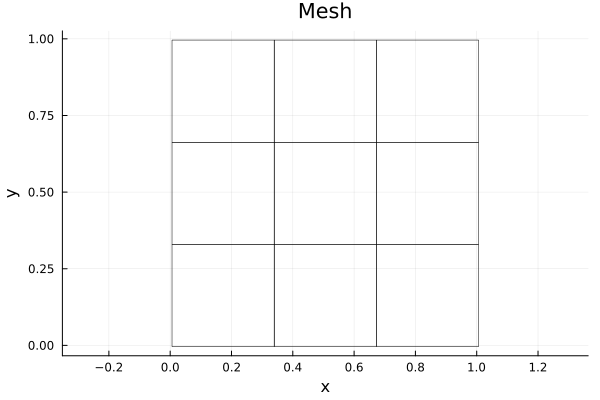

In [6]:
display(Visualization.plot_mesh(solution.state,case.mesh))

[ Info: Saved animation to c:\Users\Peikai_Li\Desktop\lagrangian_ofdg_2d_simple_release\results\constant_density.gif


Plots.AnimatedGif("c:\\Users\\Peikai_Li\\Desktop\\lagrangian_ofdg_2d_simple_release\\results\\constant_density.gif")
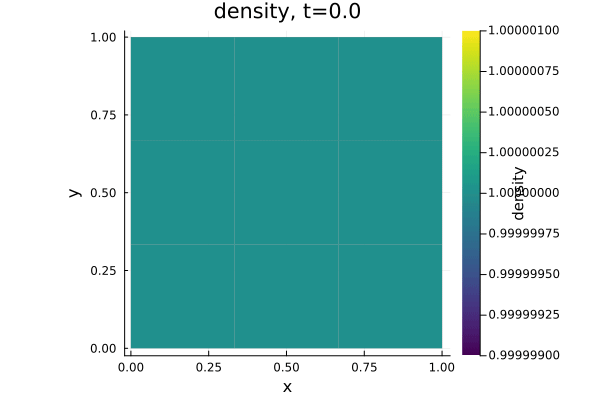

[ Info: Saved animation to c:\Users\Peikai_Li\Desktop\lagrangian_ofdg_2d_simple_release\results\constant_pressure.gif


Plots.AnimatedGif("c:\\Users\\Peikai_Li\\Desktop\\lagrangian_ofdg_2d_simple_release\\results\\constant_pressure.gif")
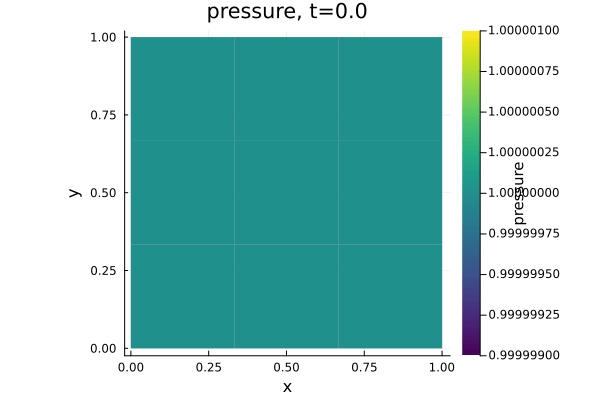

[ Info: Saved animation to c:\Users\Peikai_Li\Desktop\lagrangian_ofdg_2d_simple_release\results\constant_velocity_x.gif


Plots.AnimatedGif("c:\\Users\\Peikai_Li\\Desktop\\lagrangian_ofdg_2d_simple_release\\results\\constant_velocity_x.gif")
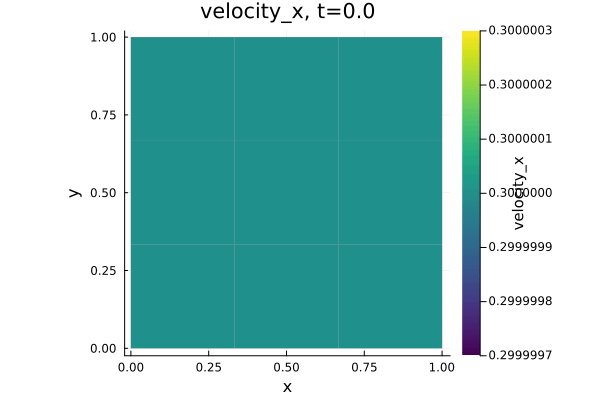

[ Info: Saved animation to c:\Users\Peikai_Li\Desktop\lagrangian_ofdg_2d_simple_release\results\constant_velocity_y.gif


Plots.AnimatedGif("c:\\Users\\Peikai_Li\\Desktop\\lagrangian_ofdg_2d_simple_release\\results\\constant_velocity_y.gif")
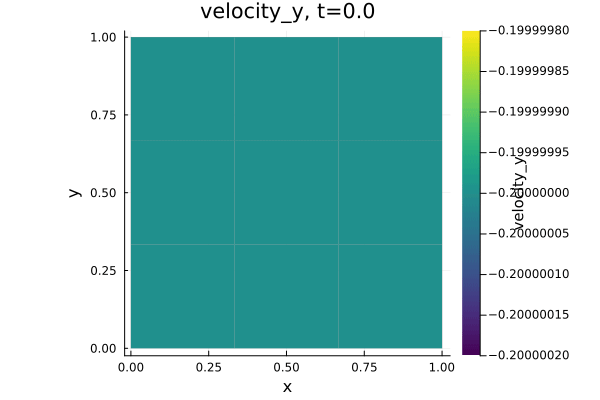

In [7]:
for field in (:density, :pressure, :velocity_x, :velocity_y)
    gif_result = Visualization.draw_gif(
        solution,
        "../results/constant_$(field).gif";
        field = field,
        fps = 10,
    )

    display(gif_result)
end

In [8]:
function constant_case_builder(nx, degree, final_time)
    return ConstantCase.make_case(
        nx = nx,
        degree = degree,
        final_time = final_time,
        cfl = 0.05,
    )
end

constant_case_builder (generic function with 1 method)

In [9]:
function convergence_study_data(case_builder; mesh_sizes_ls=[4, 8, 16], degree=2,
                        final_time=0.1, time_method=:RK4, dt_max=Inf)

    rows_ls = NamedTuple[]

    for nx in mesh_sizes_ls
        case = case_builder(nx, degree, final_time) # case::Discretization.DGCase
        solution = Solver.raw_solve_2d(case; time_method=time_method, dt_max=dt_max)
        errors = Diagnostics.smooth_error_norms(solution.state, case, solution.time)
        order_ls = fill(NaN, 4)
        if !isempty(rows_ls)
            previous = rows_ls[end]
            for component_index in 1:4
                if previous.L2_ls[component_index] > 0 && errors.L2_ls[component_index] > 0
                    order_ls[component_index] = log(previous.L2_ls[component_index] / errors.L2_ls[component_index]) / log(nx / previous.nx)
                end
            end
        end

        # first one just push 
        push!(rows_ls, (nx=nx, degree=degree, L1_ls=errors.L1_ls, L2_ls=errors.L2_ls,
                    Linf_ls=errors.Linf_ls, order_ls=order_ls,
                    number_of_steps=solution.number_of_steps, number_of_retries=solution.number_of_retries))
    end

    return rows_ls

end
converge_data = convergence_study_data(constant_case_builder)

3-element Vector{NamedTuple}:
 (nx = 4, degree = 2, L1_ls = [6.255989690508924e-16, 5.730430388091546e-16, 5.37040048566903e-16, 2.041919748136574e-15], L2_ls = [7.951100498048241e-16, 7.570971046896978e-16, 6.766994738768108e-16, 2.586805396244484e-15], Linf_ls = [2.6645352591003757e-15, 2.942091015256665e-15, 3.4139358007223564e-15, 8.881784197001252e-15], order_ls = [NaN, NaN, NaN, NaN], number_of_steps = 13, number_of_retries = 0)
 (nx = 8, degree = 2, L1_ls = [3.1310828519710288e-15, 3.1864207919496733e-15, 9.125776504813783e-16, 1.0047970212920216e-14], L2_ls = [5.487140995038464e-15, 6.1851403566715774e-15, 1.3364716656801897e-15, 1.9007068302650554e-14], Linf_ls = [2.631228568361621e-14, 4.618527782440651e-14, 9.298117831235686e-15, 9.414691248821327e-14], order_ls = [-2.786828186857484, -3.0302560778751473, -0.9818420795729237, -2.8772925941153438], number_of_steps = 25, number_of_retries = 0)
 (nx = 16, degree = 2, L1_ls = [9.161800951972802e-15, 6.140660107949372e-15, 4.7326

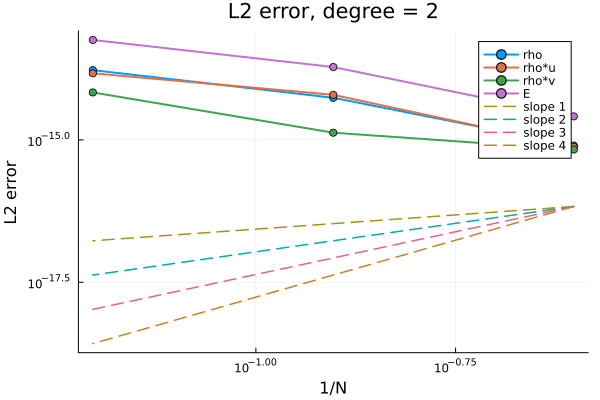

3-element Vector{NamedTuple}:
 (nx = 4, degree = 2, L1_ls = [6.255989690508924e-16, 5.730430388091546e-16, 5.37040048566903e-16, 2.041919748136574e-15], L2_ls = [7.951100498048241e-16, 7.570971046896978e-16, 6.766994738768108e-16, 2.586805396244484e-15], Linf_ls = [2.6645352591003757e-15, 2.942091015256665e-15, 3.4139358007223564e-15, 8.881784197001252e-15], order_ls = [NaN, NaN, NaN, NaN], number_of_steps = 13, number_of_retries = 0)
 (nx = 8, degree = 2, L1_ls = [3.1310828519710288e-15, 3.1864207919496733e-15, 9.125776504813783e-16, 1.0047970212920216e-14], L2_ls = [5.487140995038464e-15, 6.1851403566715774e-15, 1.3364716656801897e-15, 1.9007068302650554e-14], Linf_ls = [2.631228568361621e-14, 4.618527782440651e-14, 9.298117831235686e-15, 9.414691248821327e-14], order_ls = [-2.786828186857484, -3.0302560778751473, -0.9818420795729237, -2.8772925941153438], number_of_steps = 25, number_of_retries = 0)
 (nx = 16, degree = 2, L1_ls = [9.161800951972802e-15, 6.140660107949372e-15, 4.7326

In [ ]:
# using Plots
# function convergence_study_plot(converge_data)
#     rows_ls = converge_data
#     degree = rows_ls[1].degree
#     # Plot the L2 err
#     inverse_n_ls = [1.0 / row.nx for row in rows_ls]
#     labels_ls = ["rho", "rho*u", "rho*v", "E"]

#     figure = plot(
#         xscale = :log10,
#         yscale = :log10,
#         xlabel = "1/N",
#         ylabel = "L2 error",
#         title = "L2 error, degree = $degree",
#         legend = :best,
#     )

#     for component_index in 1:4
#         errors_ls = [row.L2_ls[component_index] for row in rows_ls]
#         plot!(
#             figure,
#             inverse_n_ls,
#             errors_ls;
#             label = labels_ls[component_index],
#             marker = :circle,
#             linewidth = 2,
#         )
#     end

#     display(figure)

#     return rows_ls
# end

Diagnostics.convergence_study_plot(converge_data)
# just for testing, it is meanless just some mechine error